20-7-2026
Day-19(21)
Monday

In [41]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [42]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

print(f"OpenCV Version: {cv2.__version__}")
print(f"Numpy Version: {np.__version__}")

OpenCV Version: 5.0.0
Numpy Version: 2.5.0


In [43]:
def show_digits(image,title="Handwritten Digit",cmap="gray"):
    plt.figure(figsize=(3,3))
    plt.imshow(image,cmap=cmap)
    plt.title(title,fontsize=11,fontweight='bold')
    plt.axis('off')
    plt.show()

def show_digit_grid(images,labels,cols=5,figsize=(12,3)):
    fig,axes=plt.subplots(1,cols,figsize=figsize)
    for i in range(cols):
        axes[i].imshow(images[i],cmap="gray")
        axes[i].set_title(f"Label: {labels[i]}",fontsize=10,fontweight='bold')
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

Total Handwritten Images in Dataset: 1797
Single Image Shape: (8, 8) (8 rows by 8 columns)


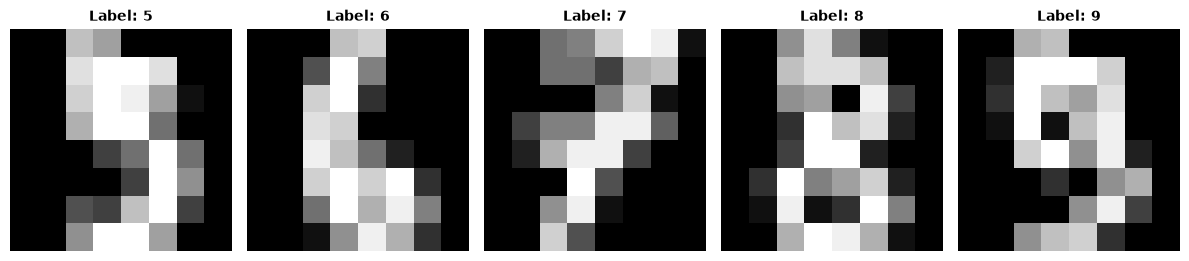

In [44]:
digits=load_digits()
x_raw=digits.images
y_raw=digits.target
print(f"Total Handwritten Images in Dataset: {len(x_raw)}")
print(f"Single Image Shape: {x_raw[0].shape} (8 rows by 8 columns)")

show_digit_grid(x_raw[5:10],y_raw[5:10],cols=5)

In [45]:
sample_digit=x_raw[0]
print("--- Pixel Matrix of handwritten Digit '0' ---")
print(sample_digit.astype(int))
print(f"\nMin Pixel Intensity (Background): {sample_digit.min()}")
print(f"Max Pixel Intensity (Ink): {sample_digit.max()}")

--- Pixel Matrix of handwritten Digit '0' ---
[[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]

Min Pixel Intensity (Background): 0.0
Max Pixel Intensity (Ink): 15.0


In [46]:
#21-7-26 
# Tuesday Day-20(22)

opencv uses BGR and matplotlib uses rgb
we convert from BGR to RGB using cv2.cvtColor(imag,cv2.COLOR_BGR2RGB)

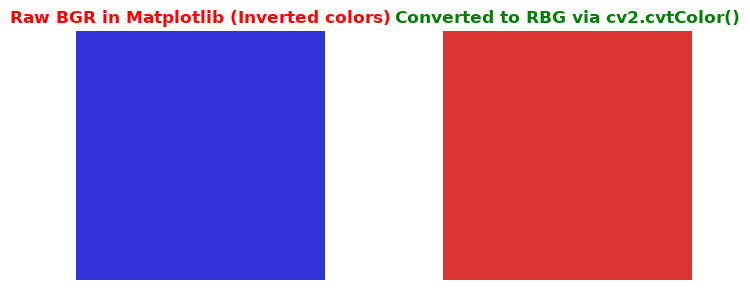

In [47]:
color_digit=cv2.cvtColor((sample_digit*15).astype(np.uint8),cv2.COLOR_GRAY2BGR)
color_digit[:,:,0]=50 #Blue channel
color_digit[:,:,1]=50 #green channel
color_digit[:,:,2]=220 #red channel

rgb_digit=cv2.cvtColor(color_digit,cv2.COLOR_BGR2RGB)

fig,axes=plt.subplots(1,2,figsize=(8,3))
axes[0].imshow(color_digit)
axes[0].set_title("Raw BGR in Matplotlib (Inverted colors)", color='red',fontweight='bold')
axes[0].axis('off')

axes[1].imshow(rgb_digit)
axes[1].set_title("Converted to RBG via cv2.cvtColor()",color='green',fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

Original Shape: (8, 8)
Resized Shape: (32, 32)


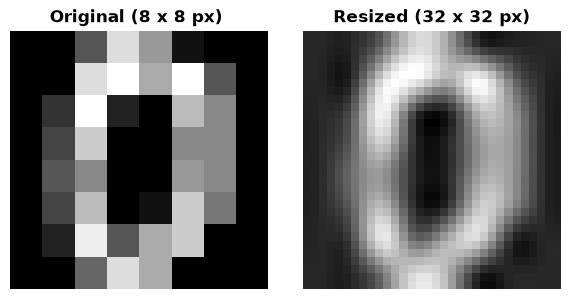

In [48]:
#Image resizing
# using cv2.resize()

digit_small=x_raw[0]
digit_resized=cv2.resize(digit_small,(32,32),interpolation=cv2.INTER_CUBIC)

print(f"Original Shape: {digit_small.shape}")
print(f"Resized Shape: {digit_resized.shape}")

fig,axes=plt.subplots(1,2,figsize=(6,3))
axes[0].imshow(digit_small,cmap='gray')
axes[0].set_title("Original (8 x 8 px) ",fontweight='bold')
axes[0].axis('off')

axes[1].imshow(digit_resized,cmap='gray')
axes[1].set_title("Resized (32 x 32 px)",fontweight='bold')
axes[1].axis('off')
plt.tight_layout()
plt.show()

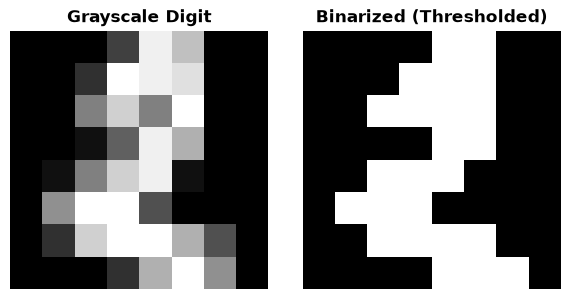

In [49]:
# image threshold and binarization using cv2.threshold()
uint8_digit=(x_raw[2] * 15).astype(np.uint8)

_, thresh_binary=cv2.threshold(uint8_digit,100,255,cv2.THRESH_BINARY)

fig,axes=plt.subplots(1,2,figsize=(6,3))
axes[0].imshow(uint8_digit,cmap='gray')
axes[0].set_title("Grayscale Digit",fontweight='bold')
axes[0].axis('off')
axes[1].imshow(thresh_binary,cmap='gray')
axes[1].set_title("Binarized (Thresholded)",fontweight='bold')
axes[1].axis('off')
plt.tight_layout()
plt.show()

Total Cpntours Found: 1
Digit Bounding Box: x=1,y=0,width=6,height=8


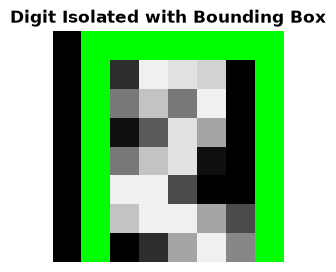

In [50]:
#isolatinf the written digits
contours, _=cv2.findContours(thresh_binary,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
print(f"Total Cpntours Found: {len(contours)}")
bbox_canvas=cv2.cvtColor(uint8_digit,cv2.COLOR_GRAY2BGR)

if len(contours)>0:
    cnt=max(contours,key=cv2.contourArea)
    x,y,w,h=cv2.boundingRect(cnt)

    cv2.rectangle(bbox_canvas,(x,y),(x+w,y+h),(0,255,0),1)
    print(f"Digit Bounding Box: x={x},y={y},width={w},height={h}")

plt.figure(figsize=(3,3))
plt.imshow(cv2.cvtColor(bbox_canvas,cv2.COLOR_BGR2RGB))
plt.title("Digit Isolated with Bounding Box",fontweight='bold')
plt.axis('off')
plt.show()

In [51]:
x_raw.shape

(1797, 8, 8)

In [52]:
# TRaining a machine learner classifier

x_features=x_raw.reshape(len(x_raw),-1)
y_labels=y_raw
x_train,x_test,y_train,y_test=train_test_split(x_features,y_labels,test_size=0.2,random_state=42)
model=KNeighborsClassifier(n_neighbors=3)
model.fit(x_train,y_train)

y_pred=model.predict(x_test)
accuracy=accuracy_score(y_test,y_pred)*100

print(f" Accuracy : {accuracy:.2f} %")

 Accuracy : 98.33 %


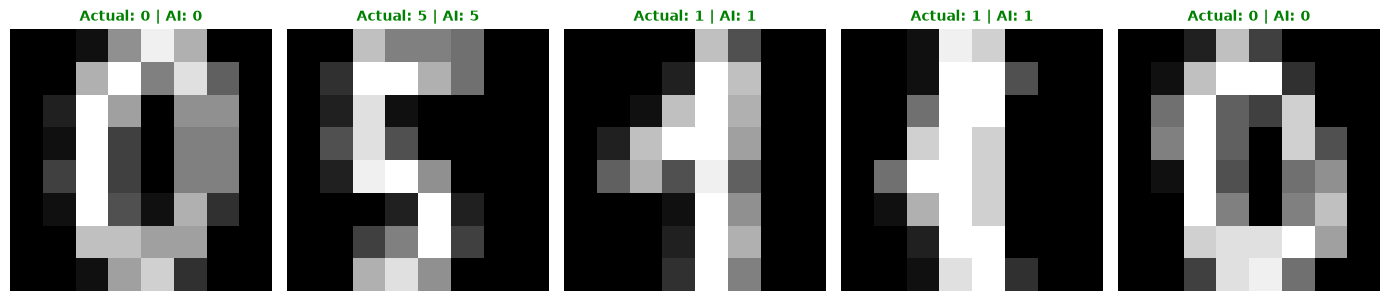

In [53]:
def predict_digit_from_image(raw_image):
    if len(raw_image.shape)==3:
        gray=cv2.cvtColor(raw_image,cv2.COLOR_BGR2GRAY)
    else:
        gray=raw_image.copy()
    gray_resized=cv2.resize(gray,(8,8),interpolation=cv2.INTER_AREA)
    # prepare 2D feature vector for ML
    feature_vector=gray_resized.reshape(1,-1)
    # model prediction
    predicted_digit=model.predict(feature_vector)[0]

    return predicted_digit,gray_resized

sample_indices=[10,25,42,99,150]

fig,axes=plt.subplots(1,5,figsize=(14,3))
for i,idx in enumerate(sample_indices):
    test_img=x_raw[idx]
    actual_label=y_raw[idx]

    predicted_label,processed_img=predict_digit_from_image(test_img)
    axes[i].imshow(test_img,cmap='gray')
    axes[i].set_title(f"Actual: {actual_label} | AI: {predicted_label}",
                      color='green' if actual_label == predicted_label else 'red',
                      fontweight='bold',fontsize=10)
    axes[i].axis('off')

plt.tight_layout()
plt.show()